In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from smodels.experiment.databaseObj import Database
from smodels.experiment.expAuxiliaryFuncs import rescaleWidth, unscaleWidth
from smodels.base.physicsUnits import GeV, pb

In [ ]:
# ------------------------- Physical configurations -------------------------
# Keep the two widths in distinct configuration variables: broad-cell execution must not
# silently change the input to an earlier narrow-width calculation.
narrow_width_fraction = 0.0099  # 0.99% (shown explicitly, not rounded to 1%)
broad_width_fraction = 0.20     # 20%

narrow_mass_range_gev = (2000, 5000)
narrow_mass_step_gev = 20.0
narrow_ylim_fb = (1e-4, 1e2)

broad_xlim_gev = (2000, 5000)
broad_ylim_fb = (7e-4, 3e3)

output_dir = Path('../paper_plots')
output_dir.mkdir(parents=True, exist_ok=True)

# Each SModelS analysis has a topology (TxName) corresponding to a final state.
# TRV1jj: spin-1 s-channel resonance -> light jets; TRV1tt: -> top pairs.
# A curve in one final state is NOT an upper limit in the other final state.
colors = plt.cm.tab20.colors
narrow_analyses = {
    'CMS-EXO-19-012': dict(txname='TRV1jj', channel='dijet', color=colors[8], ls='-'),
    'ATLAS-EXOT-2019-03': dict(txname='TRV1jj', channel='dijet', color=colors[6], ls='-'),
    'ATLAS-EXOT-2018-48': dict(txname='TRV1tt', channel=r'$t\bar t$', color=colors[2], ls='-'),
}
broad_analysis = 'CMS-EXO-19-012'  # Only its 20%-width TRV1jj map is used below.

# Input benchmark cross sections are in pb; plotting helpers convert pb -> fb..
narrow_benchmark = {
    'mass_gev': 3000.0,
    'sigma_tt_pb': 0.00013259*9.978330e-01, #sigma_pp2Z' * BR(Z'->ttbar)
    'sigma_jj_pb': 0.00013259*2*1.083506e-03 #sigma_pp2Z' * BR(Z'->qqbar)
}
broad_benchmark = {'mass_gev': 3000.0, 'sigma_jj_pb': 0.0011321*2*4.629702e-04}  # sigma_pp2Z' * BR(Z'->qqbar)


plt.rcParams.update({'savefig.dpi': 300, 'text.usetex': True,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica']})
sns.set_style('ticks', {'font.family': 'Times New Roman', 'font.serif': 'Times New Roman'})
sns.set_context('paper', font_scale=1.8)

## Loading the SModelS database upper-limits

In [9]:
# Load the official upper-limit results once and reuse the CMS map later for
# the independent broad-width calculation. No SLHA/model-point scan is needed.
db = Database('official')
exp_results = db.getExpResults(analysisIDs=list(narrow_analyses), dataTypes=['upperLimit'])


def find_txname(results, analysis_id, tx_name):
    """Find exactly one upper-limit TxName map for (analysis, final state)."""
    matches = [tx for exp in results if exp.globalInfo.id == analysis_id
               for tx in exp.getTxNames() if tx.txName == tx_name]
    if len(matches) != 1:
        raise ValueError(f'{analysis_id}/{tx_name}: expected 1 map, found {len(matches)}')
    return matches[0]


# Cache by analysis ID, so the narrow and broad sections share the same source.
tx_maps = {analysis: find_txname(exp_results, analysis, cfg['txname'])
           for analysis, cfg in narrow_analyses.items()}


def upper_limit_pb(tx, mass_gev, width_fraction):
    """Return a stored UL (pb) interpolated at a physical (mass, width) point."""
    # SModelS `dataMap` orders the *flat interpolation coordinates*.
    # For these resonance maps both coordinates are GeV: mass and totalwidth.
    point = []
    for axis in sorted(tx.dataMap):
        _, attribute, unit = tx.dataMap[axis]
        if attribute == 'mass':
            physical_value_gev = mass_gev
        elif attribute == 'totalwidth':
            physical_value_gev = mass_gev * width_fraction
        else:
            raise ValueError(f'Unsupported database coordinate: {attribute}')

        # Convert to the map's units before applying its internal width scaling.
        value = (physical_value_gev * GeV).asNumber(unit)
        point.append(rescaleWidth(value) if attribute == 'totalwidth' else value)

    ul = tx.getULFor(sms=None, mass=point)
    return np.nan if ul is None else ul.asNumber(pb)


narrow_masses = np.arange(narrow_mass_range_gev[0],
                          narrow_mass_range_gev[1] + narrow_mass_step_gev/2,
                          narrow_mass_step_gev)
narrow_limits_df = pd.DataFrame(
    [(analysis, m, upper_limit_pb(tx_maps[analysis], m, narrow_width_fraction))
     for analysis in narrow_analyses for m in narrow_masses],
    columns=['analysis', 'mass_gev', 'ul_pb'],
)

# Diagnostics: map coverage matters; in particular, missing ATLAS high-mass
# points are not zero limits and must never be extrapolated.
for analysis in narrow_analyses:
    tx = tx_maps[analysis]
    valid = narrow_limits_df.loc[
        (narrow_limits_df.analysis == analysis) & narrow_limits_df.ul_pb.gt(0)
    ]
    print(f'{analysis} / {tx.txName}: {len(valid)}/{len(narrow_masses)} mass points; '
          f'dataMap={tx.dataMap}')
if not np.isfinite(narrow_limits_df.ul_pb).any():
    raise RuntimeError('No valid narrow upper limits returned: check database and width.')

CMS-EXO-19-012 / TRV1jj: 151/151 mass points; dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2019-03 / TRV1jj: 76/151 mass points; dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2018-48 / TRV1tt: 151/151 mass points; dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}


## Shared plotting helpers



In [10]:
pb_to_fb = 1e3


def plot_upper_limits(ax, curves_df, selected_analyses, fill_top_fb):
    """Draw observed UL curves from a uniform table with ULs in pb."""
    for analysis in selected_analyses:
        cfg = narrow_analyses[analysis]  # CMS style is also used for the broad plot.
        curve = curves_df.loc[curves_df.analysis == analysis].sort_values('mass_gev')
        x = curve.mass_gev.to_numpy(dtype=float)
        y = curve.ul_pb.to_numpy(dtype=float) * pb_to_fb
        valid = np.isfinite(y) & (y > 0)
        y = np.where(valid, y, np.nan)  # Do not connect/extrapolate missing points.

        ax.plot(x, y, lw=2.2, color=cfg['color'], ls=cfg['ls'],
                label=f'{analysis} ({cfg["channel"]})')
        ax.fill_between(x, y, fill_top_fb, where=valid,
                        color=cfg['color'], alpha=0.15)


def add_benchmark(ax, mass_gev, sigma_pb, color='black', label='Benchmark'):
    """Overlay a model prediction supplied in pb, displayed in fb."""
    ax.scatter(mass_gev, sigma_pb * pb_to_fb, s=95, marker='o',
               color=color, zorder=5, label=label)


def style_limit_plot(ax, *, ylabel, title, xlim, ylim, yticks):
    """Common presentation settings; each scenario specifies its own axes."""
    ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
    ax.set_ylabel(ylabel, fontsize=23)
    ax.set_title(title, fontsize=23)
    ax.set_yscale('log')
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_yticks(yticks)
    ax.tick_params(axis='both', labelsize=23)
    ax.legend(loc='lower right', framealpha=0, fontsize=20)


def save_and_show(fig, filename):
    fig.tight_layout()
    fig.savefig(output_dir / filename, bbox_inches='tight')
    plt.show()

### Narrow dijet limits and dijet benchmark



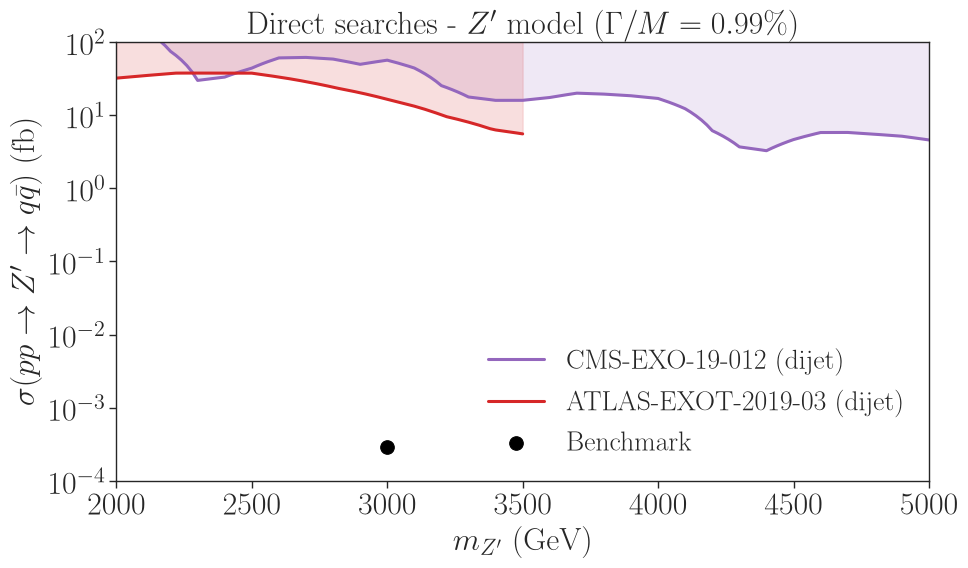

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_upper_limits(ax, narrow_limits_df,
                  ['CMS-EXO-19-012', 'ATLAS-EXOT-2019-03'],
                  fill_top_fb=narrow_ylim_fb[1])
add_benchmark(ax, narrow_benchmark['mass_gev'], narrow_benchmark['sigma_jj_pb'])
style_limit_plot(ax,
    ylabel=r'$\sigma(pp\to Z^\prime\to q\bar q)$ (fb)',
    title=r"Direct searches - $Z'$ model ($\Gamma/M=0.99\%$)",
    xlim=narrow_mass_range_gev, ylim=narrow_ylim_fb,
    yticks=[1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2])
save_and_show(fig, 'directSearches_Zprime_qq.png')

### Narrow $t\bar t$ limit and $t\bar t$ benchmark


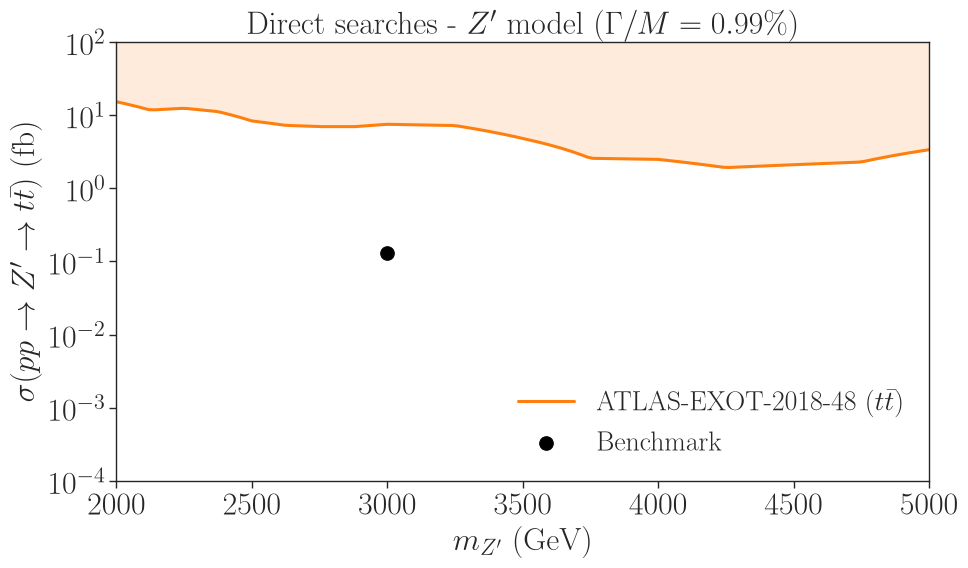

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_upper_limits(ax, narrow_limits_df, ['ATLAS-EXOT-2018-48'],
                  fill_top_fb=narrow_ylim_fb[1])
add_benchmark(ax, narrow_benchmark['mass_gev'], narrow_benchmark['sigma_tt_pb'])
style_limit_plot(ax,
    ylabel=r'$\sigma(pp\to Z^\prime\to t\bar t)$ (fb)',
    title=r"Direct searches - $Z'$ model ($\Gamma/M=0.99\%$)",
    xlim=narrow_mass_range_gev, ylim=narrow_ylim_fb,
    yticks=[1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2])
save_and_show(fig, 'directSearches_Zprime_tt.png')

## Broad $Z'$ (20%): directly select the tabulated CMS dijet points



CMS broad UL at 3000 GeV (tabulated):   107.302500 fb
CMS broad UL at 3000 GeV (interpolated): 107.176000 fb
20% width grid: 43 points, 1800 to 6000 GeV


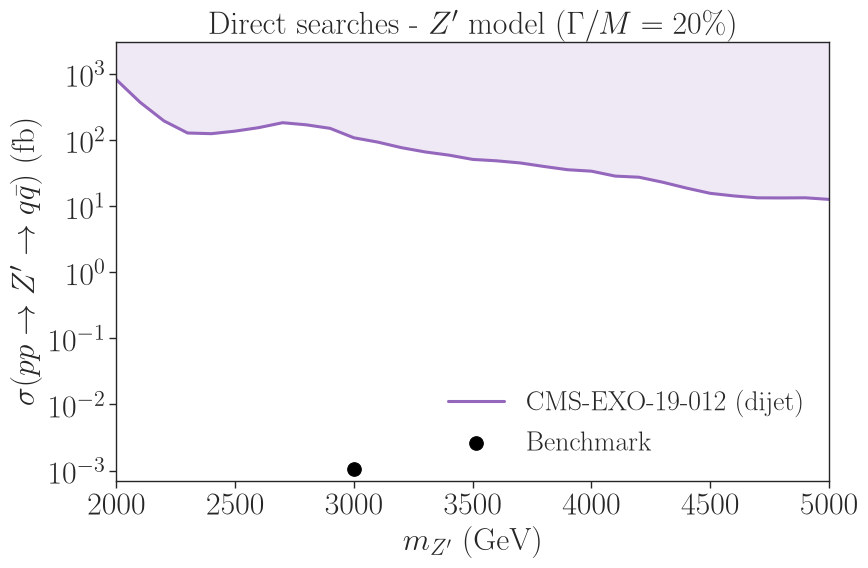

In [13]:
# Reuse precisely the same database object/map as in the narrow section.
broad_tx = tx_maps[broad_analysis]
broad_data = broad_tx.txnameData

# Restore physical mass and width coordinates of all TABULATED points.
# (No interpolation and no extrapolation are involved in this selection.)
physical_grid = np.asarray(
    [broad_data.inversePCAtransf(p) for p in broad_data.tri.points], dtype=float
)
if physical_grid.ndim != 2 or physical_grid.shape[1] != 2:
    raise ValueError(f'Expected (mass, width) coordinates; got shape {physical_grid.shape}')
if len(physical_grid) != len(broad_data.y_values):
    raise ValueError('Mismatch between stored grid points and upper-limit values.')

mass_grid_gev = physical_grid[:, 0]
width_grid_gev = np.array([unscaleWidth(w) for w in physical_grid[:, 1]])
ul_grid_pb = np.array([(value * broad_tx.y_unit).asNumber(pb)
                       for value in broad_data.y_values])

# Keep only the *broad* 20% slice and preserve the correspondence between
# its masses and SModelS UL values (all cross sections remain in pb here).
mask_20pc = np.isclose(width_grid_gev / mass_grid_gev,
                       broad_width_fraction, rtol=1e-7)
broad_limits_df = pd.DataFrame({
    'analysis': broad_analysis,
    'mass_gev': mass_grid_gev[mask_20pc],
    'ul_pb': ul_grid_pb[mask_20pc],
}).sort_values('mass_gev').reset_index(drop=True)
if broad_limits_df.empty:
    raise RuntimeError('CMS-EXO-19-012 contains no tabulated 20%-width entries.')

# Cross-check the source extraction at an existing database grid point.
# The source notebook found 107.3025 fb at (m, Gamma) = (3000, 600) GeV.
check = broad_limits_df.loc[np.isclose(broad_limits_df.mass_gev, 3000), 'ul_pb']
if not check.empty:
    observed_fb = check.iloc[0] * pb_to_fb
    interpolated_fb = upper_limit_pb(broad_tx, 3000, broad_width_fraction) * pb_to_fb
    print(f'CMS broad UL at 3000 GeV (tabulated):   {observed_fb:.6f} fb')
    print(f'CMS broad UL at 3000 GeV (interpolated): {interpolated_fb:.6f} fb')
    if not np.isclose(observed_fb, interpolated_fb, rtol=1e-3):
        print('WARNING: grid and interpolation do not agree within 0.1%.')
print(f'20% width grid: {len(broad_limits_df)} points, '
      f'{broad_limits_df.mass_gev.min():g} to {broad_limits_df.mass_gev.max():g} GeV')

# Exactly the same plotting conventions/functions as in the narrow panels.
fig, ax = plt.subplots(figsize=(9, 6))
plot_upper_limits(ax, broad_limits_df, [broad_analysis],
                  fill_top_fb=broad_ylim_fb[1])
add_benchmark(ax, broad_benchmark['mass_gev'], broad_benchmark['sigma_jj_pb'])
style_limit_plot(ax,
    ylabel=r'$\sigma(pp\to Z^\prime\to q\bar q)$ (fb)',
    title=r"Direct searches - $Z'$ model ($\Gamma/M=20\%$)",
    xlim=broad_xlim_gev, ylim=broad_ylim_fb,
    yticks=[1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
save_and_show(fig, 'directSearches_Zprime_broad_qq.png')